# 02 · Recreación del análisis y comparación con el artículo (Etapas 5–6)

Se aplica **el mismo procedimiento** de Tapia et al. (2025) a los 52.039 anuncios que los autores publicaron en Mendeley Data (`data_paper_plosone_set.csv`) y se contrasta cada resultado con lo que reporta el artículo.

| Elemento | Artículo / código de los autores | Aquí |
|---|---|---|
| Objetivo | ln(1 + precio en UF) (`np.log1p`) | igual |
| Algoritmo ML | LightGBM (DART, 8.000 iteraciones) + SHAP | LightGBM con los **mismos hiperparámetros** de los autores, pero *boosting* GBDT y 400 árboles (DART con 8.000 iteraciones tarda horas; `notebooks/colab/` lo ejecuta); TreeSHAP |
| Econométricos | OLS con errores de White y SAR por 2SLS espacial (`spreg.GM_Lag`), W: KNN k = 700 | OLS (HC1) y SAR por 2SLS (implementación propia, instrumentos WX y W²X), W: KNN k = 700 |
| Validación | 5-fold CV (semilla 123); partición Training/Test del conjunto para SHAP | igual: semilla 123 y la columna `set` del conjunto |
| Métricas | MAPE, MdAPE, MAE, RMSE, R² (en UF) | las mismas, más mediana de la razón, COD y PRD |
| Autocorrelación | I de Moran (esda, 999 permutaciones) | I de Moran propio con W dispersa (199 permutaciones) |

**Desviaciones declaradas:** (1) GBDT con 400 árboles en lugar de DART con 8.000 (el error de DART converge a un valor algo menor: ver `notebooks/colab/lgbm_section_colab.ipynb`, que sí lo ejecuta); (2) el artículo no detalla cómo predice el SAR fuera de muestra: en las tablas principales se usa la forma reducida (I − ρW)⁻¹Xβ, que sólo requiere coordenadas, y en la sección 5d se prueba una variante que usa los precios de los vecinos de entrenamiento; (3) no se repite la selección variable por variable: se usa el conjunto final de la Tabla 4 y la secuencia de la Tabla 3.

In [1]:
import sys, time
sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C, analisis as A, figuras as F
from src.datos_reales import cargar_reales
from src.modelos import cv_sar_vecinos
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
C.DIR_RESULTADOS.mkdir(exist_ok=True)

df = cargar_reales()
df.shape

d:\academico\maestria_analitica_aplicada\semestre 2\Machine Learning 2\proyecto\proyecto_ajustes\proyecto_ml_final_datos_reales\proyecto_ml_final\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(52039, 50)

## 5a · Secuencia de modelos (Tabla 3): LightGBM y validación cruzada de 5 particiones

In [2]:
t0 = time.time()
tab3 = A.tabla_secuencia(df)
tab3.to_csv(C.DIR_RESULTADOS / "tabla3_secuencia_modelos.csv", index=False)
print(f"{time.time() - t0:.0f} s")
mostrar = tab3[["modelo", "n_variables", "mejora_en_n_de_5_metricas"]].copy()
for m in C.COLS_METRICAS:
    mostrar[f"{m} artículo"] = tab3[f"{m}_art"]
    mostrar[f"{m} real"] = tab3[m]
mostrar.round(3)

120 s


,modelo,n_variables,mejora_en_n_de_5_metricas,MAPE artículo,MAPE real,MdAPE artículo,MdAPE real,MAE artículo,MAE real,RMSE artículo,RMSE real,R2 artículo,R2 real
0,Modelo base,7,NaN,11.59,11.744,7.87,8.262,906.66,919.632,1513.44,1511.704,0.941,0.941
1,M1 +quality_municipality,8,5.0,11.46,11.565,7.81,8.148,898.40,909.759,1501.93,1496.684,0.942,0.943
2,M2 +amenities,12,5.0,10.94,11.302,7.46,7.958,863.40,895.547,1448.80,1475.530,0.946,0.944
3,M3 +new_house,13,5.0,10.88,11.238,7.44,7.919,860.92,892.376,1446.02,1468.517,0.946,0.945
4,M4 +simce_4b,14,5.0,10.72,11.190,7.30,7.838,849.60,888.295,1430.32,1462.530,0.948,0.945
5,M5 +nearby_schools_3km,15,5.0,10.63,11.111,7.23,7.791,844.36,881.928,1424.25,1456.360,0.948,0.946
6,M6 +9 distancias,24,5.0,10.24,10.879,6.88,7.565,816.99,865.828,1391.43,1434.641,0.950,0.947
7,Final +10 fotos,34,4.0,10.07,10.848,6.84,7.672,807.53,865.554,1373.23,1430.862,0.952,0.947


Reducción del error por agregar las 10 variables de fotos (%)


,métrica,artículo,real
0,MAE,1.2,0.03
1,MAPE,1.7,0.29
2,RMSE,1.3,0.26


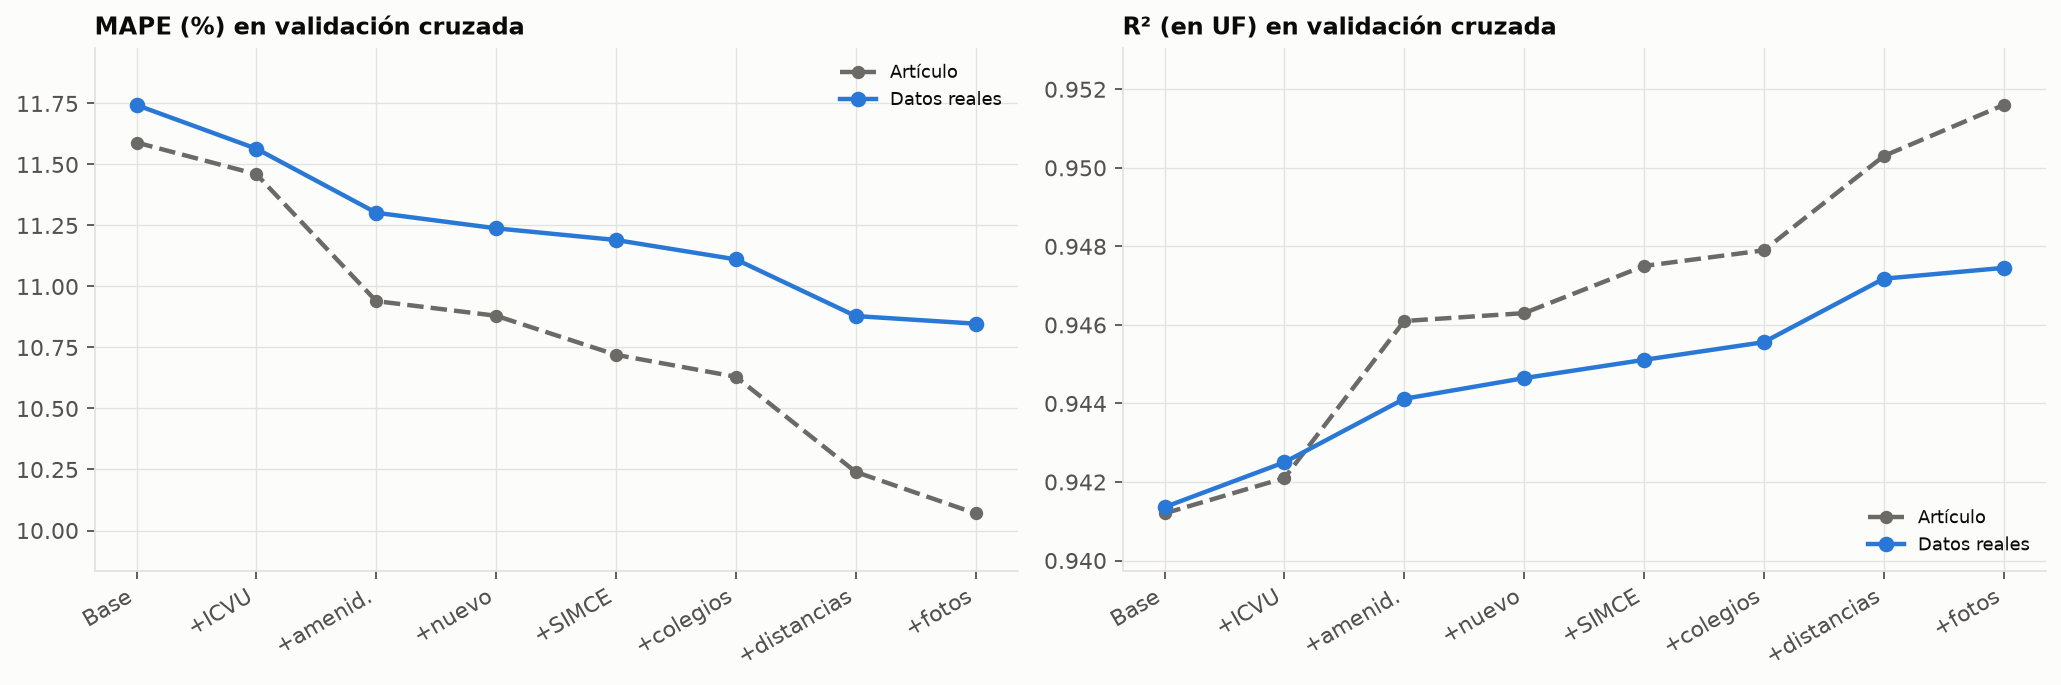

In [3]:
u, p = tab3.iloc[-1], tab3.iloc[-2]
tabla_fotos = pd.DataFrame({"métrica": ["MAE", "MAPE", "RMSE"], "artículo": [1.2, 1.7, 1.3],
                            "real": [100 * (p[m] - u[m]) / p[m] for m in ("MAE", "MAPE", "RMSE")]})
print("Reducción del error por agregar las 10 variables de fotos (%)")
display(tabla_fotos.round(2))
display(Image(str(F.fig_secuencia({"real": tab3}))))

## 5b · Modelo final con partición Training/Test e interpretación con SHAP (Tabla 5, Figs 3–7)

In [4]:
t0 = time.time()
final = A.modelo_final_shap(df)
print(f"{time.time() - t0:.0f} s")
pd.DataFrame({"artículo (Tabla 5, DART 8.000)": C.REPORTADO_TABLA5,
              "real (GBDT 400)": [final["metricas"][m] for m in C.COLS_METRICAS]}, index=C.COLS_METRICAS).round(4)

20 s


,"artículo (Tabla 5, DART 8.000)",real (GBDT 400)
MAPE,10.0400,10.8103
MdAPE,6.7700,7.5719
MAE,797.9900,854.7716
RMSE,1358.8000,1405.3978
R2,0.9525,0.9492


In [5]:
final["importancia"].head(12).round(4).rename_axis("variable").to_frame("mean|SHAP| (ln precio)")

,mean|SHAP| (ln precio)
variable,
total_surface,0.3022
simce_4b,0.2740
quality_municipality,0.1229
bathrooms,0.1117
latitude,0.0414
longitude,0.0201
dist_university,0.0167
dist_industry,0.0153
swimpool,0.0147


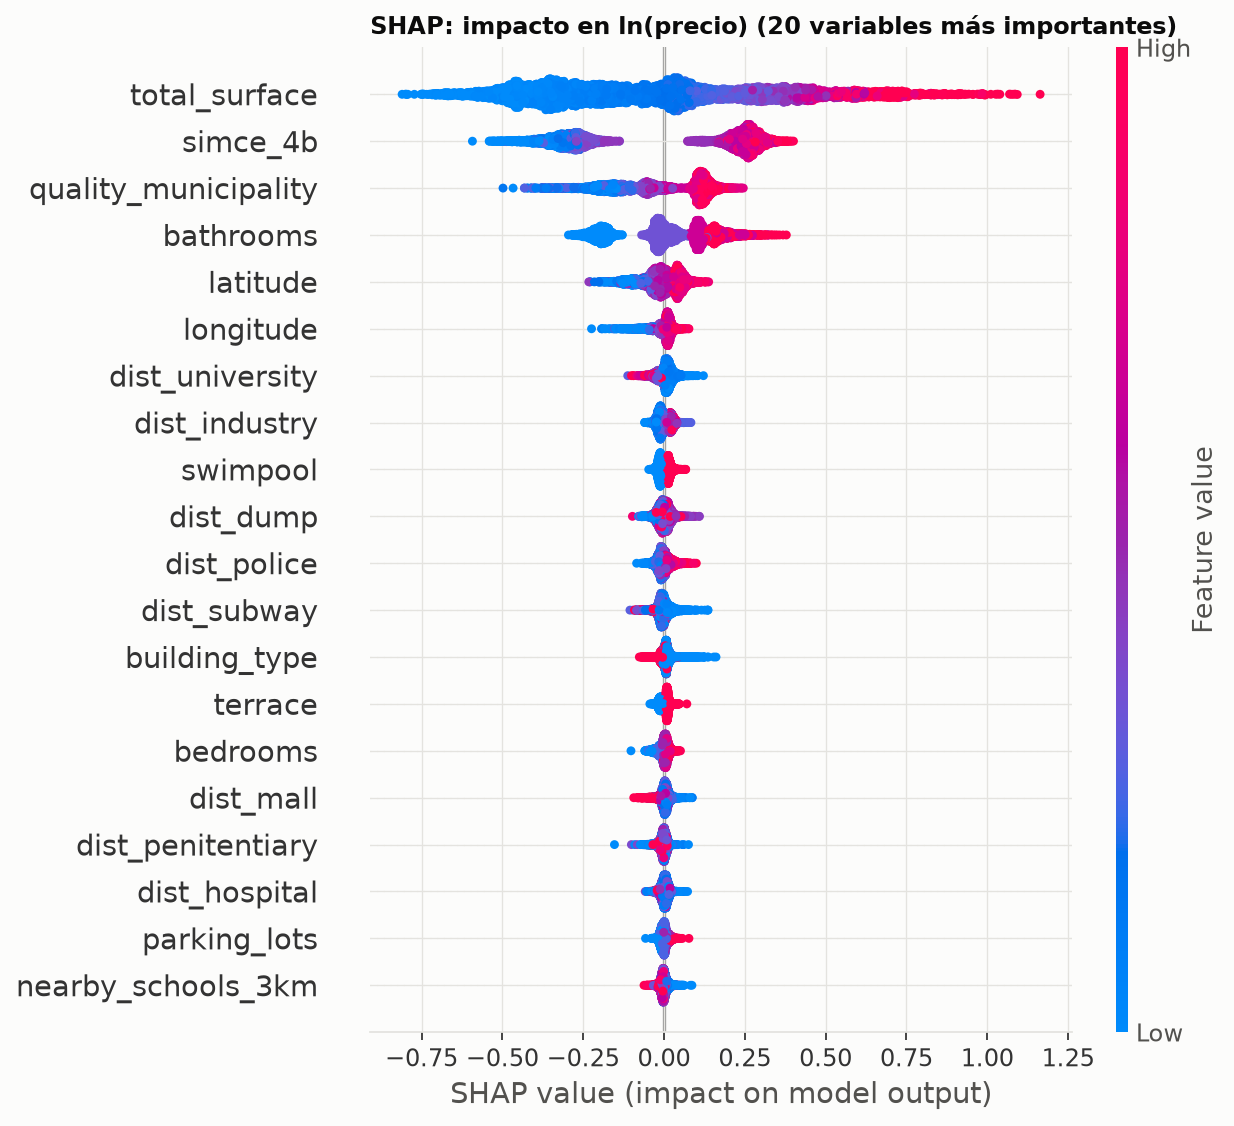

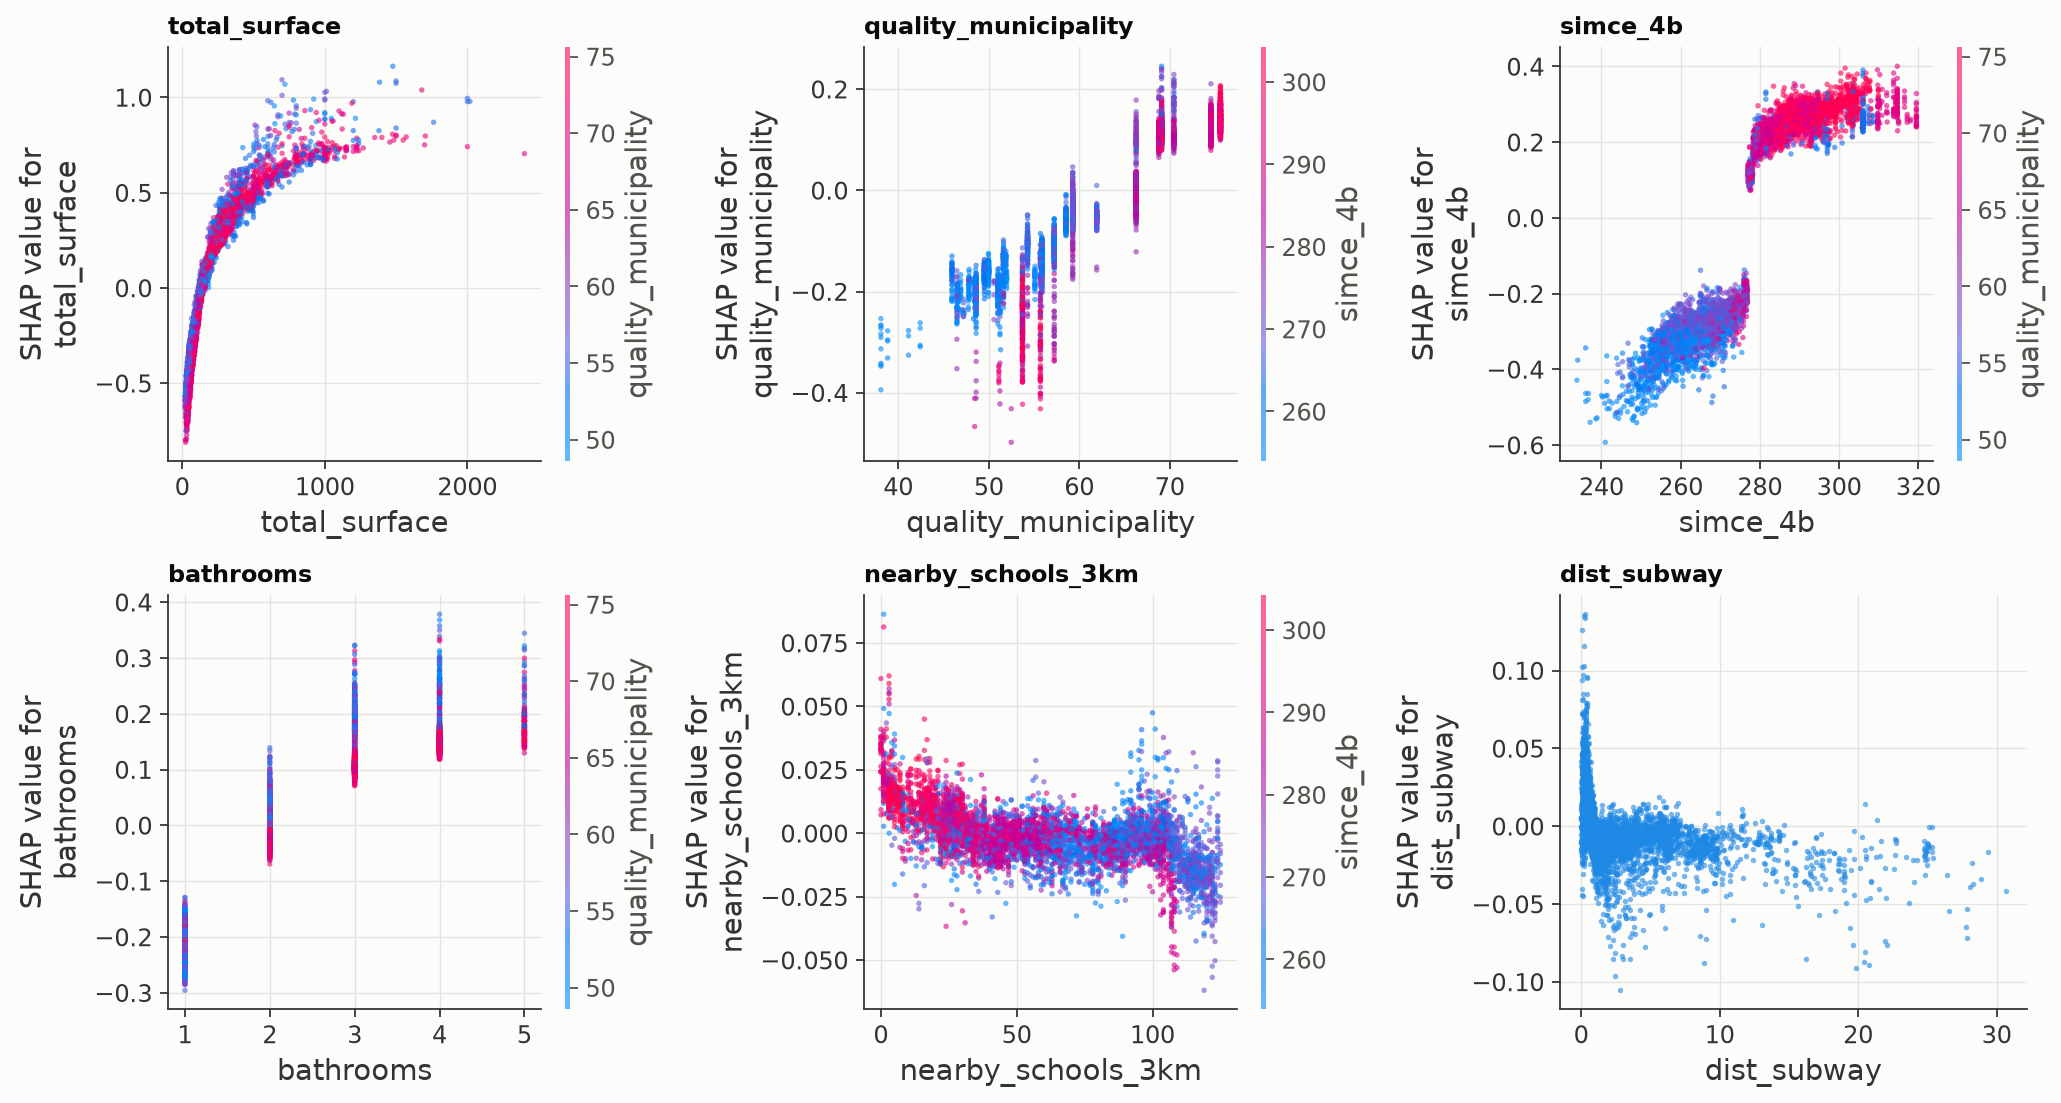

In [6]:
display(Image(str(F.fig_shap_beeswarm(final, "real"))))
display(Image(str(F.fig_shap_dependencia(final, "real"))))

## 5c · Modelos econométricos: OLS y SAR (Tablas 6–9) e I de Moran

In [7]:
t0 = time.time()
econ = A.comparar_econometricos(df, permutaciones=199)
print(f"{time.time() - t0:.0f} s")
pd.DataFrame({
    "rho SAR": [C.RHO_REPORTADO, econ["sar"]["rho"]],
    "R² OLS (log)": [C.REPORTADO_R2_INSAMPLE["OLS"], econ["ols"].rsquared],
    "R² SAR (log)": [C.REPORTADO_R2_INSAMPLE["SAR"], econ["sar"]["R2_insample"]],
    **{f"I Moran {k}": [v, econ["moran"][k][0]] for k, v in C.REPORTADO_MORAN.items()},
}, index=["artículo", "real"]).round(4).T

75 s


,artículo,real
rho SAR,0.4271,0.4351
R² OLS (log),0.8654,0.8663
R² SAR (log),0.8774,0.8787
I Moran ln(price),0.7107,0.7108
I Moran residuos OLS,0.1337,0.1423
I Moran residuos SAR,0.0751,0.0788


In [8]:
c = econ["coef"]
coef = pd.DataFrame({"variable": c["variable"], "OLS artículo": c["OLS_art"], "OLS real": c["OLS_est"],
                     "SAR artículo": c["SAR_art"], "SAR real": c["SAR_est"]})
coef["mismo signo SAR"] = np.sign(coef["SAR real"]) == np.sign(coef["SAR artículo"])
coef.to_csv(C.DIR_RESULTADOS / "tabla8_coeficientes_ols_sar.csv", index=False)
print("Coeficientes SAR con el mismo signo que el artículo:", int(coef["mismo signo SAR"].sum()), "de", len(coef))
coef.round(4)

Coeficientes SAR con el mismo signo que el artículo: 33 de 33


,variable,OLS artículo,OLS real,SAR artículo,SAR real,mismo signo SAR
0,constant,3.7782,3.7878,1.9507,1.9329,True
1,bathrooms,0.1798,0.1780,0.1712,0.1688,True
2,bedrooms,0.0814,0.0828,0.0752,0.0763,True
3,building_type,0.0874,0.0847,0.0957,0.0920,True
4,seller_type,-0.0662,-0.0672,-0.0649,-0.0653,True
5,total_surface,0.0008,0.0008,0.0007,0.0007,True
6,quality_municipality,0.0273,0.0271,0.0178,0.0175,True
7,parking_lots,0.0159,0.0163,0.0139,0.0137,True
8,swimpool,0.0002,-0.0010,0.0021,0.0025,True
9,terrace,0.0582,0.0595,0.0465,0.0470,True


## 5d · ¿Cómo predice el SAR fuera de muestra? (variante)
La Tabla 9 del artículo da para SAR un MAPE de 20,92 % y R² de 0,741, algo mejor que OLS. Con la forma reducida (que ignora los precios de los vecinos) el SAR queda **peor** que OLS en los datos reales. Como el artículo no explica cómo se predice, se prueba la otra forma habitual: ŷ = Xβ + ρ·(promedio del ln(precio) de los vecinos de entrenamiento), que equivale a valorar por comparables. Es una **elección de este proyecto**, no algo confirmado en el artículo.

In [9]:
t0 = time.time()
sar_v = cv_sar_vecinos(df)
print(f"{time.time() - t0:.0f} s")
sar_var = pd.DataFrame({"artículo (Tabla 9)": dict(zip(C.COLS_METRICAS, C.REPORTADO_TABLA9["SAR"])),
                        "real: forma reducida": econ["cv"]["SAR"], "real: con precios de vecinos": sar_v})
sar_var.to_csv(C.DIR_RESULTADOS / "sar_variante_prediccion.csv")
sar_var.round(3)

13 s


,artículo (Tabla 9),real: forma reducida,real: con precios de vecinos
MAPE,20.92,22.203,20.501
MdAPE,17.13,17.141,15.861
MAE,1893.09,2049.772,1844.395
RMSE,3115.85,3761.556,3304.663
R2,0.74,0.637,0.720


## Etapa 6 · Comparación de resultados: artículo vs. datos reales

In [10]:
comp = A.tabla_comparacion_resultados({"real": (final, econ)})
comp.to_csv(C.DIR_RESULTADOS / "comparacion_articulo_vs_real.csv", index=False)
comp.round(4)

,resultado,métrica,artículo,real,dif_real
0,Tabla 5 LightGBM holdout 80/20,MAPE,10.0400,10.8103,0.7703
1,Tabla 5 LightGBM holdout 80/20,MdAPE,6.7700,7.5719,0.8019
2,Tabla 5 LightGBM holdout 80/20,MAE,797.9900,854.7716,56.7816
3,Tabla 5 LightGBM holdout 80/20,RMSE,1358.8000,1405.3978,46.5978
4,Tabla 5 LightGBM holdout 80/20,R2,0.9525,0.9492,-0.0033
5,Tabla 9 OLS 5-fold CV,MAPE,21.1300,21.8456,0.7156
6,Tabla 9 OLS 5-fold CV,MdAPE,16.8600,17.2892,0.4292
7,Tabla 9 OLS 5-fold CV,MAE,1887.8500,1949.6727,61.8227
8,Tabla 9 OLS 5-fold CV,RMSE,3356.5000,3517.6907,161.1907
9,Tabla 9 OLS 5-fold CV,R2,0.7103,0.6827,-0.0276


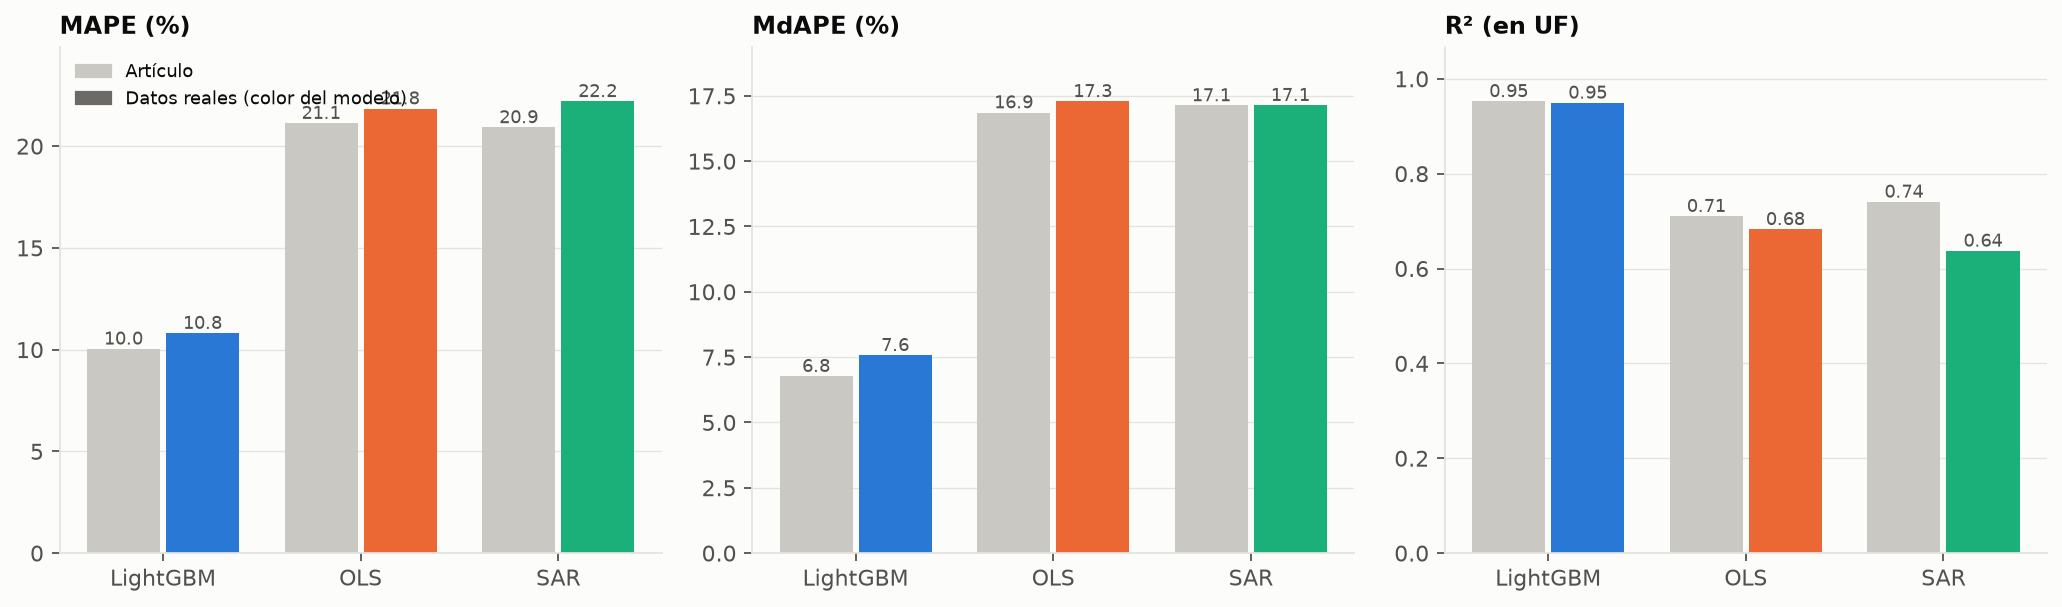

In [11]:
display(Image(str(F.fig_comparacion_modelos(comp))))

### Ranking de importancia de variables (Tabla 10)

In [12]:
rank = A.tabla_ranking(final["importancia"], econ["imp_ols"], econ["imp_sar"], top=15)
rank.to_csv(C.DIR_RESULTADOS / "tabla10_ranking_importancia.csv", index=False)
coinc = pd.DataFrame([{"modelo": m, "top-5 obtenido": ", ".join(rank[m][:5]), "top-5 del artículo": ", ".join(C.REPORTADO_TOP5[m]),
                       "coinciden": len(set(rank[m][:5]) & set(C.REPORTADO_TOP5[m]))} for m in ("LightGBM+SHAP", "OLS", "SAR")])
display(rank)
coinc

,pos,LightGBM+SHAP,OLS,SAR
0,1,total_surface,quality_municipality,bathrooms
1,2,simce_4b,bathrooms,quality_municipality
2,3,quality_municipality,total_surface,total_surface
3,4,bathrooms,simce_4b,bedrooms
4,5,dist_university,bedrooms,simce_4b
5,6,dist_industry,dist_university,nearby_schools_3km
6,7,swimpool,building_type,building_type
7,8,dist_dump,dist_industry,dist_university
8,9,dist_police,storage_units,storage_units
9,10,dist_subway,nearby_schools_3km,terrace


,modelo,top-5 obtenido,top-5 del artículo,coinciden
0,LightGBM+SHAP,"total_surface, simce_4b, quality_municipality,...","total_surface, quality_municipality, simce_4b,...",5
1,OLS,"quality_municipality, bathrooms, total_surface...","quality_municipality, bathrooms, total_surface...",5
2,SAR,"bathrooms, quality_municipality, total_surface...","bathrooms, quality_municipality, total_surface...",5


In [13]:
# Efecto de la cercanía de colegios (hallazgo central del artículo): signo en cada enfoque
sh = final["shap"][:, C.VARS_FINAL.index("nearby_schools_3km")]
x = final["Xs"]["nearby_schools_3km"].values
cc = econ["coef"].set_index("variable")
pd.DataFrame([{"conjunto": "artículo", "OLS": -0.0008, "SAR": 0.0014, "pendiente SHAP": np.nan},
              {"conjunto": "real", "OLS": cc.loc["nearby_schools_3km", "OLS_est"], "SAR": cc.loc["nearby_schools_3km", "SAR_est"],
               "pendiente SHAP": np.polyfit(x, sh, 1)[0]}]).set_index("conjunto").round(5)

,OLS,SAR,pendiente SHAP
conjunto,,,
artículo,-0.00080,0.00140,NaN
real,-0.00083,0.00145,-0.00018
